In [9]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Инициализация генератора случайных чисел для воспроизводимости
keras.utils.set_random_seed(42)

In [10]:
# Загрузка данных
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Нормализация данных (приведение к диапазону от 0 до 1)
x_train = x_train / 255.0
x_test = x_test / 255.0

In [11]:
# Определение входного слоя
input_layer = keras.Input(shape=(28, 28))

# Преобразование матрицы 28x28 в вектор
h = keras.layers.Flatten()(input_layer)

# Первый скрытый слой
h = keras.layers.Dense(256, activation="relu", name="Hidden_1")(h)

# ВТОРОЙ скрытый слой (дополнительный)
h = keras.layers.Dense(256, activation="relu", name="Hidden_2")(h)

# Выходной слой (10 классов)
output_layer = keras.layers.Dense(10, activation="softmax", name="Output")(h)

# Сборка модели
model = keras.Model(inputs=input_layer, outputs=output_layer)

# Вывод структуры модели
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_1 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_2 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 269,322 (1.03 MB)

 Trainable params: 269,322 (1.03 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

In [13]:
batch_size = 64
epochs = 20

history = model.fit(
    x_train,
    y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_split=0.2
)

Epoch 1/20


W0000 00:00:1793446969.560097    9890 cpu_allocator_impl.cc:82] Allocation of 150528000 exceeds 10% of free system memory.


743/750 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8219 - loss: 0.4977

W0000 00:00:1793446973.150049    9890 cpu_allocator_impl.cc:82] Allocation of 37632000 exceeds 10% of free system memory.


750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8219 - loss: 0.4972 - val_accuracy: 0.8599 - val_loss: 0.3875
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8678 - loss: 0.3644 - val_accuracy: 0.8659 - val_loss: 0.3643
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8803 - loss: 0.3261 - val_accuracy: 0.8695 - val_loss: 0.3628
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8887 - loss: 0.2999 - val_accuracy: 0.8745 - val_loss: 0.3602
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8951 - loss: 0.2803 - val_accuracy: 0.8788 - val_loss: 0.3473
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9004 - loss: 0.2642 - val_accuracy: 0.8774 - val_loss: 0.3435
Epoch 7/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9060 - loss: 0.2499 - val_accuracy: 0.8827 - val_loss: 0.3329
Epoch 8/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9114 - loss: 0.2364 - val_accuracy: 0.8802 - val_

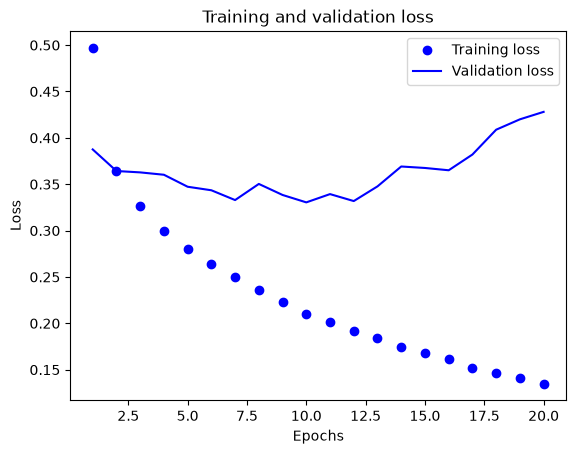

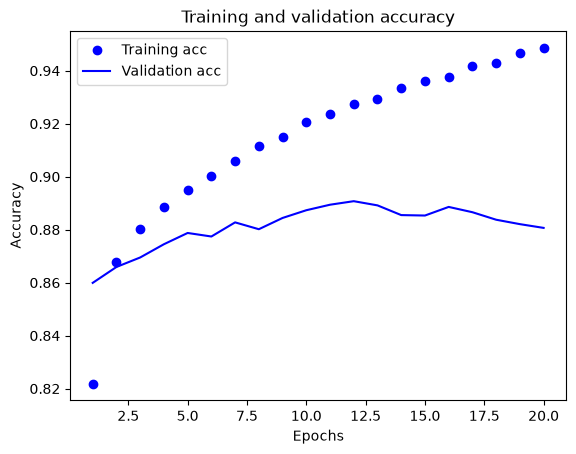

In [14]:
def plot_loss_curves(history):
    plt.clf()
    history_dict = history.history
    loss_values = history_dict["loss"]
    val_loss_values = history_dict["val_loss"]
    epochs = range(1, len(loss_values) + 1)
    plt.plot(epochs, loss_values, "bo", label="Training loss")
    plt.plot(epochs, val_loss_values, "b", label="Validation loss")
    plt.title("Training and validation loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

def plot_acc_curves(history):
    plt.clf()
    history_dict = history.history
    acc = history_dict["accuracy"]
    val_acc = history_dict["val_accuracy"]
    epochs = range(1, len(acc) + 1)
    plt.plot(epochs, acc, "bo", label="Training acc")
    plt.plot(epochs, val_acc, "b", label="Validation acc")
    plt.title("Training and validation accuracy")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()

# Вызов функций для отрисовки
plot_loss_curves(history)
plot_acc_curves(history)

In [15]:
# Оценка модели
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Точность на тестовых данных: {test_acc:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8724 - loss: 0.4711
Точность на тестовых данных: 0.8724
